# 03 · Modelagem
Fase 4 do CRISP-DM: **K-Means** para encontrar perfis de desejo e **similaridade do cosseno** para comparar pessoas.

> ⚠️ **Dados fictícios.** Enquanto a coleta real não termina, este notebook usa
> `data/processed/desejos_demo.csv`, gerado por `src/exemplo.py`: 12 pessoas inventadas a partir de
> 4 estilos de desejo (gastronômico, tech, moda, pet), mais o perfil de exemplo "você".
> **Para usar os dados reais:** baixe o CSV anonimizado no app (*Meus Desejos → Baixar CSV anonimizado*),
> salve como `data/processed/desejos.csv` e troque `ARQUIVO` na célula abaixo. O resto roda igual.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # para importar src/

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette=["#6D4AFF", "#E8701F", "#17975F", "#C13B7A", "#2A7AB8", "#8C8A9E"])
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)

In [2]:
from src.clustering import escolher_k, agrupar, NOMES
perfis = pd.read_csv(Path.cwd().parent / "data" / "processed" / "perfis_demo.csv", index_col="usuario")
perfis

,animais,bebidas,beleza,brinquedos e games,calçados,casa e decoração,comida,eletrônicos,esporte e lazer,livros e papelaria,vestuário,veículos
usuario,,,,,,,,,,,,
u01,0.00,0.29,0.00,0.00,0.14,0.10,0.43,0.00,0.00,0.00,0.00,0.05
u02,0.00,0.17,0.00,0.00,0.00,0.04,0.65,0.00,0.00,0.00,0.00,0.13
u03,0.00,0.00,0.00,0.35,0.00,0.00,0.00,0.42,0.16,0.00,0.06,0.00
u04,0.00,0.25,0.00,0.00,0.00,0.08,0.46,0.00,0.00,0.00,0.04,0.17
u05,0.00,0.00,0.26,0.00,0.37,0.00,0.00,0.00,0.07,0.00,0.30,0.00
u06,0.55,0.00,0.00,0.00,0.00,0.00,0.14,0.09,0.18,0.05,0.00,0.00
u07,0.13,0.00,0.00,0.22,0.00,0.00,0.00,0.57,0.09,0.00,0.00,0.00
u08,0.00,0.00,0.18,0.43,0.00,0.00,0.00,0.21,0.07,0.00,0.11,0.00
u09,0.15,0.00,0.00,0.00,0.00,0.00,0.42,0.38,0.00,0.00,0.04,0.00


## 1. Quantos grupos? Cotovelo e silhueta
- **Inércia** (cotovelo): soma das distâncias de cada pessoa ao centro do seu grupo. Sempre cai com mais grupos;
  procuramos o ponto em que a queda desacelera.
- **Silhueta** (−1 a 1): o quanto cada pessoa está mais perto do próprio grupo do que do grupo vizinho.
  Quanto maior, melhor separados.

,k,inercia,silhueta
0,2,2.15,0.27
1,3,1.23,0.44
2,4,0.50,0.57
3,5,0.31,0.52
4,6,0.22,0.46


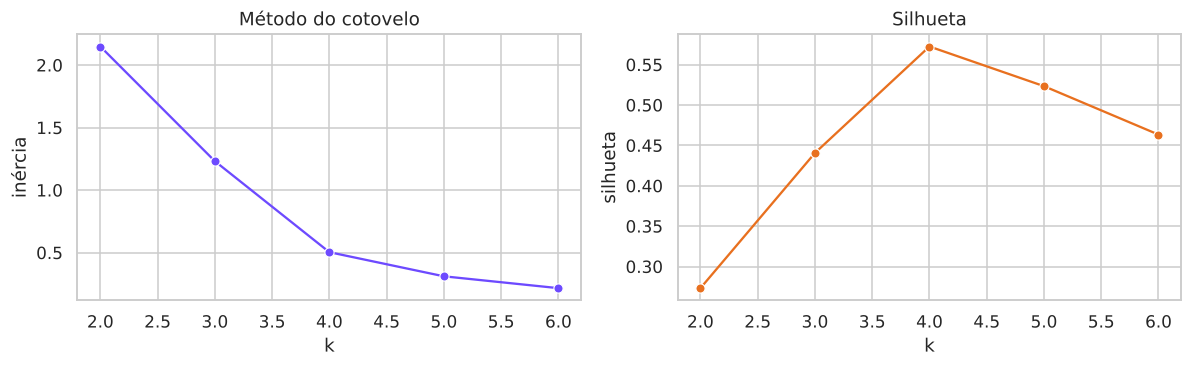

In [3]:
tabela = escolher_k(perfis)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.lineplot(data=tabela, x="k", y="inercia", marker="o", ax=ax[0], color="#6D4AFF")
ax[0].set(title="Método do cotovelo", ylabel="inércia")
sns.lineplot(data=tabela, x="k", y="silhueta", marker="o", ax=ax[1], color="#E8701F")
ax[1].set(title="Silhueta", ylabel="silhueta")
plt.tight_layout()
tabela.round(3)

> Nos dados fictícios, as pessoas foram geradas a partir de 4 estilos. Se o método funciona, ele deve
> **reencontrar esses 4 grupos** sem saber dos estilos: é um bom teste antes de usar os dados reais.

In [4]:
k = int(tabela.loc[tabela["silhueta"].idxmax(), "k"])
rotulos, centros = agrupar(perfis, k)
print(f"k escolhido pela maior silhueta: {k}")
rotulos

k escolhido pela maior silhueta: 4


,usuario,cluster,perfil
0,u01,0,Gastronômico
1,u02,0,Gastronômico
2,u03,2,Tech & Games
3,u04,0,Gastronômico
4,u05,3,Moda & Beleza
5,u06,1,Pet lover
6,u07,2,Tech & Games
7,u08,2,Tech & Games
8,u09,0,Gastronômico
9,u10,3,Moda & Beleza


## 2. O que cada grupo significa?
O nome de cada grupo vem das categorias com maior peso no seu **centro** (`src/clustering.nomear_cluster`).

Text(126.88460286458331, 0.5, '')

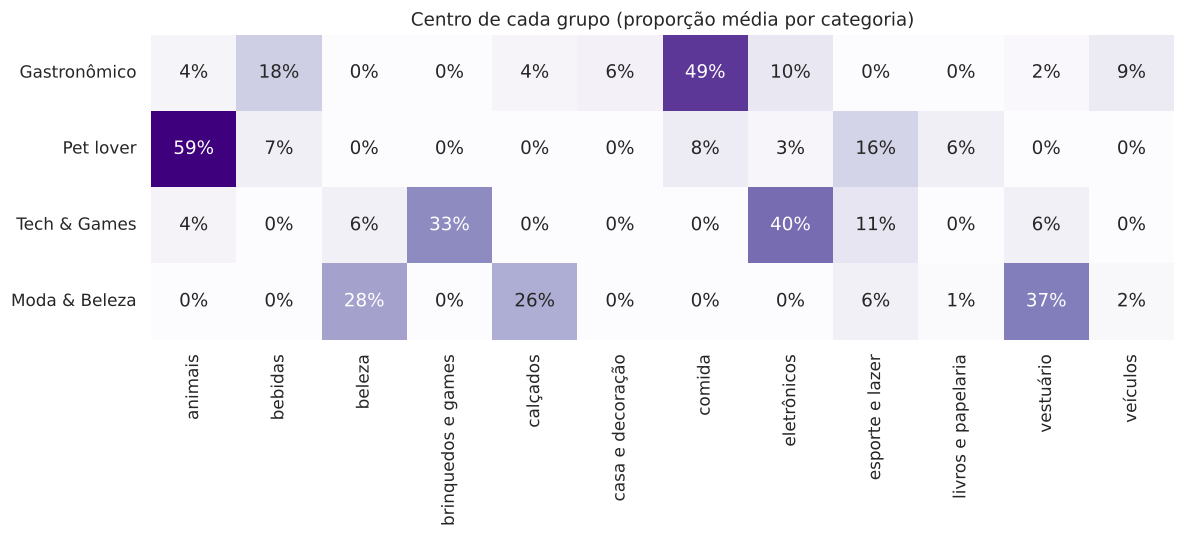

In [5]:
cols = [c for c in perfis.columns if centros[c].max() > 0.02]
plt.figure(figsize=(12, 1.2 + 0.6 * len(centros)))
sns.heatmap(centros.set_index("perfil")[cols], annot=True, fmt=".0%", cmap="Purples", cbar=False)
plt.title("Centro de cada grupo (proporção média por categoria)"); plt.xlabel(""); plt.ylabel("")

## 3. Similaridade do cosseno entre pessoas
É a base da página **Comparar** do app. Mede o ângulo entre dois vetores de perfil:
**1 (100%)** = mesma distribuição de desejos; **0** = nenhuma categoria em comum.

Text(0.5, 1.0, 'Similaridade do cosseno entre pessoas')

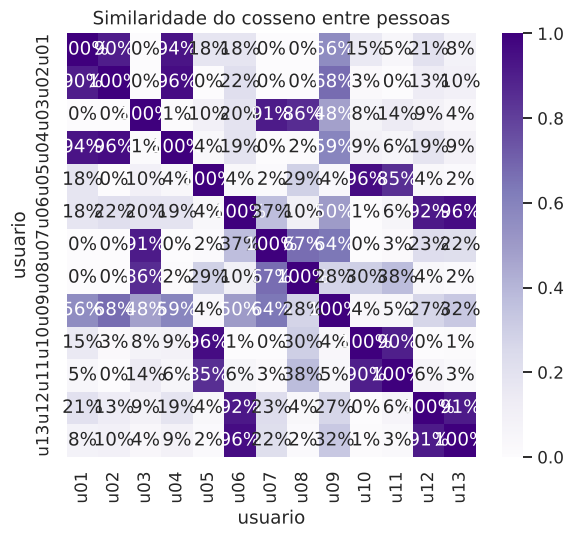

In [6]:
from sklearn.metrics.pairwise import cosine_similarity
sim = pd.DataFrame(cosine_similarity(perfis), index=perfis.index, columns=perfis.index)
plt.figure(figsize=(6, 5))
sns.heatmap(sim, annot=True, fmt=".0%", cmap="Purples", vmin=0, vmax=1)
plt.title("Similaridade do cosseno entre pessoas")

## 4. Recomendação: "pessoas parecidas com você"

In [7]:
def mais_parecidas(usuario, n=2):
    return sim[usuario].drop(usuario).sort_values(ascending=False).head(n)

for u in sim.index:
    top = mais_parecidas(u)
    print(f"{u}: " + ", ".join(f"{o} ({v:.0%})" for o, v in top.items()))

u01: u04 (94%), u02 (90%)
u02: u04 (96%), u01 (90%)
u03: u07 (91%), u08 (86%)
u04: u02 (96%), u01 (94%)
u05: u10 (96%), u11 (85%)
u06: u13 (96%), u12 (92%)
u07: u03 (91%), u08 (67%)
u08: u03 (86%), u07 (67%)
u09: u02 (68%), u07 (64%)
u10: u05 (96%), u11 (90%)
u11: u10 (90%), u05 (85%)
u12: u06 (92%), u13 (91%)
u13: u06 (96%), u12 (91%)
